이 노트북은 <[케라스 창시자에게 배우는 딥러닝 (개정 3판)](https://tensorflow.blog/kerasdl3/)>(길벗, 2026)의 예제 코드를 담고 있습니다.

## 텐서플로, 파이토치, JAX 그리고 케라스에 대한 소개

### 딥러닝 프레임워크의 간략한 역사

### 프레임워크 사이의 관계

### 텐서플로 소개

#### 텐서플로 첫걸음

##### 텐서플로의 텐서와 변수

###### 상수 텐서

In [1]:
import tensorflow as tf
tf.ones(shape=(2, 1))

<tf.Tensor: shape=(2, 1), dtype=float32, numpy=
array([[1.],
       [1.]], dtype=float32)>

In [2]:
tf.zeros(shape=(2, 1))

<tf.Tensor: shape=(2, 1), dtype=float32, numpy=
array([[0.],
       [0.]], dtype=float32)>

In [3]:
tf.constant([1, 2, 3], dtype="float32")

<tf.Tensor: shape=(3,), dtype=float32, numpy=array([1., 2., 3.], dtype=float32)>

###### 랜덤 텐서

In [4]:
x = tf.random.normal(shape=(3, 1), mean=0., stddev=1.)
print(x)

tf.Tensor(
[[1.3329251]
 [0.7453839]
 [0.9124838]], shape=(3, 1), dtype=float32)


In [5]:
x = tf.random.uniform(shape=(3, 1), minval=0., maxval=1.)
print(x)

tf.Tensor(
[[0.39041388]
 [0.6854429 ]
 [0.67231095]], shape=(3, 1), dtype=float32)


###### 텐서 할당과 Variable 클래스

In [6]:
import numpy as np

x = np.ones(shape=(2, 2))
x[0, 0] = 0.0

In [7]:
v = tf.Variable(initial_value=tf.random.normal(shape=(3, 1)))
print(v)

<tf.Variable 'Variable:0' shape=(3, 1) dtype=float32, numpy=
array([[0.86030793],
       [1.0115417 ],
       [0.34028345]], dtype=float32)>


In [8]:
v.assign(tf.ones((3, 1)))

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[1.],
       [1.],
       [1.]], dtype=float32)>

In [9]:
v[0, 0].assign(3.)

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[3.],
       [1.],
       [1.]], dtype=float32)>

In [10]:
v.assign_add(tf.ones((3, 1)))

<tf.Variable 'UnreadVariable' shape=(3, 1) dtype=float32, numpy=
array([[4.],
       [2.],
       [2.]], dtype=float32)>

##### 텐서 연산: 텐서플로로 수학 계산하기

In [11]:
a = tf.ones((2, 2))
b = tf.square(a)
c = tf.sqrt(a)
d = b + c
e = tf.matmul(a, b)
f = tf.concat((a, b), axis=0)

In [12]:
def dense(inputs, W, b):
    return tf.nn.relu(tf.matmul(inputs, W) + b)

##### 텐서플로의 그레이디언트: GradientTape API 다시 살펴 보기

In [13]:
input_var = tf.Variable(initial_value=3.0)
with tf.GradientTape() as tape:
    result = tf.square(input_var)
gradient = tape.gradient(result, input_var)

In [14]:
input_const = tf.constant(3.0)
with tf.GradientTape() as tape:
    tape.watch(input_const)
    result = tf.square(input_const)
gradient = tape.gradient(result, input_const)

In [15]:
time = tf.Variable(0.0)
with tf.GradientTape() as outer_tape:
    with tf.GradientTape() as inner_tape:
        position = 4.9 * time**2
    speed = inner_tape.gradient(position, time)
acceleration = outer_tape.gradient(speed, time)

##### 컴파일을 사용해 텐서플로 함수 속도 높이기

In [16]:
@tf.function
def dense(inputs, W, b):
    return tf.nn.relu(tf.matmul(inputs, W) + b)

In [17]:
@tf.function(jit_compile=True)
def dense(inputs, W, b):
    return tf.nn.relu(tf.matmul(inputs, W) + b)

###### [추가] 컴파일 효과 측정하기

책에는 없는 내용입니다. 같은 함수를 세 가지 방식으로 실행해 호출 시간을 비교합니다. 즉시 실행(파이썬이 연산을 하나씩 호출), `@tf.function`(그래프로 변환), `@tf.function(jit_compile=True)`(XLA로 컴파일)입니다.

In [18]:
# [추가] 즉시 실행, 그래프(@tf.function), XLA(jit_compile=True)의 호출 시간을 비교합니다.
from time import perf_counter

def timed(fn, args, n):
    """fn(*args)를 n번 호출했을 때 한 번당 걸린 시간(ms)"""
    t = perf_counter()
    for _ in range(n):
        out = fn(*args)
    out.numpy()  # GPU 연산이 끝날 때까지 기다립니다
    return (perf_counter() - t) / n * 1e3

def compare(name, fn, args, n=50):
    timed(fn, args, 3)  # 준비 운동
    eager = timed(fn, args, n)
    print(f"[{name}] 즉시 실행 {eager:.3f} ms")

    for label, compiled in [
        ("그래프", tf.function(fn)),
        ("XLA", tf.function(fn, jit_compile=True)),
    ]:
        first = timed(compiled, args, 1)  # 트레이싱과 컴파일은 첫 호출에서 일어납니다
        fast = timed(compiled, args, n)
        print(
            f"[{name}] {label} {fast:.3f} ms | {eager / fast:.2f}배 | "
            f"첫 호출(컴파일 포함) {first / 1e3:.1f} s"
        )

def plain_dense(inputs, W, b):
    return tf.nn.relu(tf.matmul(inputs, W) + b)

bench_inputs = tf.random.uniform((2000, 2))
bench_W = tf.random.uniform((2, 1))
bench_b = tf.zeros((1,))
compare("밀집 층", plain_dense, (bench_inputs, bench_W, bench_b))

[밀집 층] 즉시 실행 0.600 ms
[밀집 층] 그래프 0.757 ms | 0.79배 | 첫 호출(컴파일 포함) 0.1 s


[밀집 층] XLA 0.739 ms | 0.81배 | 첫 호출(컴파일 포함) 0.2 s


In [19]:
# [추가] 연산이 더 많은 작은 CNN으로 같은 비교를 해 봅니다.
def conv_weights(in_channels, out_channels):
    return {
        "kernel": tf.Variable(tf.random.normal((3, 3, in_channels, out_channels), stddev=0.1)),
        "scale": tf.Variable(tf.ones((out_channels,))),
        "shift": tf.Variable(tf.zeros((out_channels,))),
    }

def conv_block(x, weights):
    x = tf.nn.conv2d(x, weights["kernel"], strides=1, padding="SAME")
    x = x * weights["scale"] + weights["shift"]  # 추론 시의 배치 정규화는 채널별 스케일과 이동입니다
    return tf.nn.relu(x)

def convnet(images):
    x = conv_block(images, block1)
    x = conv_block(x, block2)
    x = tf.nn.max_pool2d(x, ksize=2, strides=2, padding="VALID")
    x = conv_block(x, block3)
    x = tf.reduce_mean(x, axis=[1, 2])
    return tf.matmul(x, head_W) + head_b

# GPU가 없거나 CPU에서 재려면 "/CPU:0"으로 바꿉니다.
device = "/GPU:0"

with tf.device(device):
    block1, block2, block3 = conv_weights(3, 32), conv_weights(32, 64), conv_weights(64, 128)
    head_W = tf.Variable(tf.random.normal((128, 10), stddev=0.1))
    head_b = tf.Variable(tf.zeros((10,)))
    images = tf.random.uniform((32, 64, 64, 3))
    compare("CNN", convnet, (images,), n=20)

[CNN] 즉시 실행 3.656 ms
[CNN] 그래프 3.425 ms | 1.07배 | 첫 호출(컴파일 포함) 0.1 s
[CNN] XLA 1.392 ms | 2.63배 | 첫 호출(컴파일 포함) 2.8 s


#### 엔드-투-엔드 예제: 순수 텐서플로로 구현하는 선형 분류기

In [20]:
import numpy as np

num_samples_per_class = 1000
negative_samples = np.random.multivariate_normal(
    mean=[0, 3], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)
positive_samples = np.random.multivariate_normal(
    mean=[3, 0], cov=[[1, 0.5], [0.5, 1]], size=num_samples_per_class
)

In [21]:
inputs = np.vstack((negative_samples, positive_samples)).astype(np.float32)

In [22]:
targets = np.vstack(
    (
        np.zeros((num_samples_per_class, 1), dtype="float32"),
        np.ones((num_samples_per_class, 1), dtype="float32"),
    )
)

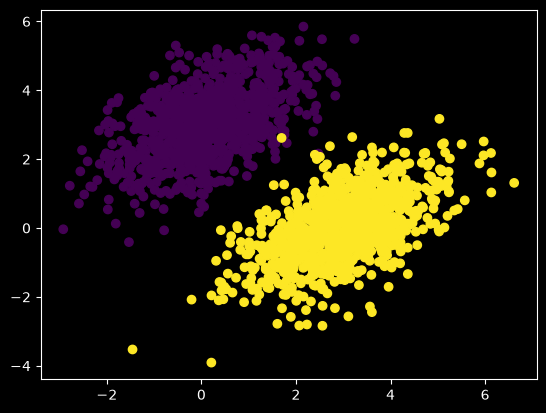

In [23]:
import matplotlib.pyplot as plt

plt.scatter(inputs[:, 0], inputs[:, 1], c=targets[:, 0])
plt.show()

In [24]:
input_dim = 2
output_dim = 1
W = tf.Variable(initial_value=tf.random.uniform(shape=(input_dim, output_dim)))
b = tf.Variable(initial_value=tf.zeros(shape=(output_dim,)))

In [25]:
def model(inputs, W, b):
    return tf.matmul(inputs, W) + b

In [26]:
def mean_squared_error(targets, predictions):
    per_sample_losses = tf.square(targets - predictions)
    return tf.reduce_mean(per_sample_losses)

In [27]:
learning_rate = 0.1

@tf.function(jit_compile=True)
def training_step(inputs, targets, W, b):
    with tf.GradientTape() as tape:
        predictions = model(inputs, W, b)
        loss = mean_squared_error(predictions, targets)
    grad_loss_wrt_W, grad_loss_wrt_b = tape.gradient(loss, [W, b])
    W.assign_sub(grad_loss_wrt_W * learning_rate)
    b.assign_sub(grad_loss_wrt_b * learning_rate)
    return loss

In [28]:
for step in range(40):
    loss = training_step(inputs, targets, W, b)
    print(f"{step}번째 스텝의 손실: {loss:.4f}")

0번째 스텝의 손실: 1.0599
1번째 스텝의 손실: 0.2433
2번째 스텝의 손실: 0.1272
3번째 스텝의 손실: 0.1026
4번째 스텝의 손실: 0.0933
5번째 스텝의 손실: 0.0869
6번째 스텝의 손실: 0.0814
7번째 스텝의 손실: 0.0765
8번째 스텝의 손실: 0.0720
9번째 스텝의 손실: 0.0679
10번째 스텝의 손실: 0.0641
11번째 스텝의 손실: 0.0607
12번째 스텝의 손실: 0.0575
13번째 스텝의 손실: 0.0547
14번째 스텝의 손실: 0.0521
15번째 스텝의 손실: 0.0497
16번째 스텝의 손실: 0.0475
17번째 스텝의 손실: 0.0455
18번째 스텝의 손실: 0.0437
19번째 스텝의 손실: 0.0420
20번째 스텝의 손실: 0.0405
21번째 스텝의 손실: 0.0391
22번째 스텝의 손실: 0.0379
23번째 스텝의 손실: 0.0367
24번째 스텝의 손실: 0.0357
25번째 스텝의 손실: 0.0347
26번째 스텝의 손실: 0.0338
27번째 스텝의 손실: 0.0330
28번째 스텝의 손실: 0.0323
29번째 스텝의 손실: 0.0316
30번째 스텝의 손실: 0.0310
31번째 스텝의 손실: 0.0305
32번째 스텝의 손실: 0.0300
33번째 스텝의 손실: 0.0295
34번째 스텝의 손실: 0.0291
35번째 스텝의 손실: 0.0287
36번째 스텝의 손실: 0.0283
37번째 스텝의 손실: 0.0280
38번째 스텝의 손실: 0.0277
39번째 스텝의 손실: 0.0274


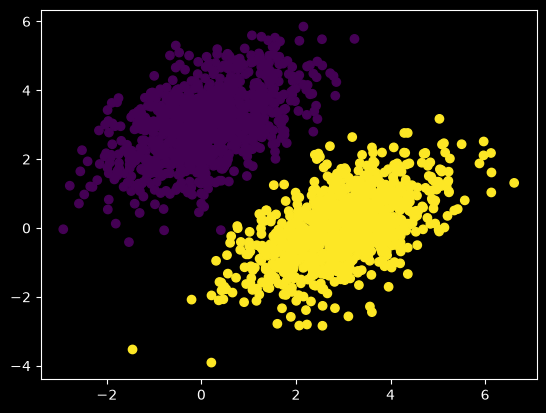

In [29]:
predictions = model(inputs, W, b)
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)
plt.show()

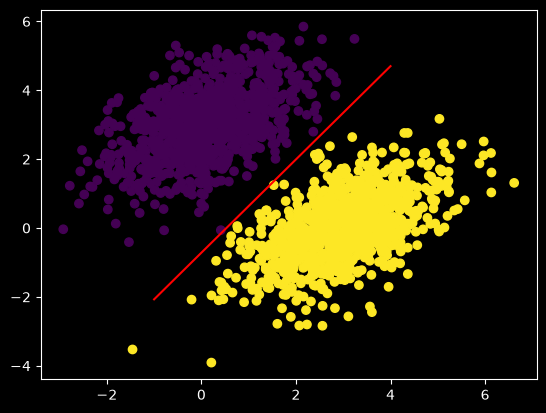

In [30]:
x = np.linspace(-1, 4, 100)
y = -W[0] / W[1] * x + (0.5 - b) / W[1]
plt.plot(x, y, "-r")
plt.scatter(inputs[:, 0], inputs[:, 1], c=predictions[:, 0] > 0.5)

#### 텐서플로 방식의 차이점